# Bài tập mở rộng — MNIST

In [1]:
from pathlib import Path
import copy
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, f1_score
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split

SEED = 42
BATCH_SIZE = 128
EPOCHS = 10
PATIENCE = 3
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


class IDXDataset(Dataset):
    def __init__(self, image_path, label_path):
        import idx2numpy
        images = idx2numpy.convert_from_file(str(image_path)).astype(np.float32) / 255.0
        labels = idx2numpy.convert_from_file(str(label_path)).astype(np.int64)
        self.images = torch.from_numpy(images)
        self.labels = torch.from_numpy(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.images[index], self.labels[index]


def load_mnist():
    data_dir = Path("mnist-dataset")
    paths = {
        "train_images": data_dir / "train-images-idx3-ubyte",
        "train_labels": data_dir / "train-labels-idx1-ubyte",
        "test_images": data_dir / "t10k-images-idx3-ubyte",
        "test_labels": data_dir / "t10k-labels-idx1-ubyte",
    }

    if all(path.exists() for path in paths.values()):
        full_train = IDXDataset(paths["train_images"], paths["train_labels"])
        test = IDXDataset(paths["test_images"], paths["test_labels"])
    else:
        from torchvision.datasets import MNIST
        from torchvision.transforms import ToTensor
        full_train = MNIST(root="mnist_data", train=True, download=True, transform=ToTensor())
        test = MNIST(root="mnist_data", train=False, download=True, transform=ToTensor())

    validation_size = 6_000
    train_size = len(full_train) - validation_size
    train, validation = random_split(
        full_train,
        [train_size, validation_size],
        generator=torch.Generator().manual_seed(SEED),
    )
    return train, validation, test


train_dataset, validation_dataset, test_dataset = load_mnist()
PIN_MEMORY = DEVICE.type == "cuda"
print(f"Device: {DEVICE} | Train: {len(train_dataset):,} | Validation: {len(validation_dataset):,} | Test: {len(test_dataset):,}")

Device: cpu | Train: 54,000 | Validation: 6,000 | Test: 10,000


In [2]:
class LinearClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 10),
        )

    def forward(self, x):
        return self.network(x)


class MLPClassifier(nn.Module):
    def __init__(self, use_dropout=True):
        super().__init__()
        dropout_1 = nn.Dropout(0.2) if use_dropout else nn.Identity()
        dropout_2 = nn.Dropout(0.2) if use_dropout else nn.Identity()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            dropout_1,
            nn.Linear(256, 128),
            nn.ReLU(),
            dropout_2,
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.network(x)


def build_model(model_name, use_dropout=True):
    if model_name == "linear":
        return LinearClassifier()
    if model_name == "mlp":
        return MLPClassifier(use_dropout=use_dropout)
    raise ValueError("model_name phải là 'linear' hoặc 'mlp'.")


def count_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)


def make_loaders():
    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
        pin_memory=PIN_MEMORY,
    )
    train_eval_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        pin_memory=PIN_MEMORY,
    )
    validation_loader = DataLoader(
        validation_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        pin_memory=PIN_MEMORY,
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        pin_memory=PIN_MEMORY,
    )
    return train_loader, train_eval_loader, validation_loader, test_loader


def train_one_epoch(model, dataloader, loss_fn, optimizer):
    model.train()
    total_loss = 0.0
    total_samples = 0

    for images, labels in dataloader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

    return total_loss / total_samples


def evaluate(model, dataloader, loss_fn):
    model.eval()
    total_loss = 0.0
    total_samples = 0
    labels_all = []
    predictions_all = []

    with torch.inference_mode():
        for images, labels in dataloader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            logits = model(images)
            loss = loss_fn(logits, labels)
            predictions = logits.argmax(dim=1)

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_samples += batch_size
            labels_all.extend(labels.cpu().numpy())
            predictions_all.extend(predictions.cpu().numpy())

    labels_all = np.asarray(labels_all)
    predictions_all = np.asarray(predictions_all)
    return {
        "loss": total_loss / total_samples,
        "f1": f1_score(labels_all, predictions_all, average="macro", zero_division=0),
        "labels": labels_all,
        "predictions": predictions_all,
    }


def run_experiment(
    name,
    model_name,
    learning_rate,
    optimizer_name="adam",
    use_dropout=True,
    track_train=False,
):
    set_seed()
    train_loader, train_eval_loader, validation_loader, test_loader = make_loaders()
    model = build_model(model_name, use_dropout=use_dropout).to(DEVICE)
    loss_fn = nn.CrossEntropyLoss()

    if optimizer_name == "adam":
        optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    elif optimizer_name == "sgd":
        optimizer = torch.optim.SGD(
            model.parameters(),
            lr=learning_rate,
            momentum=0.9,
        )
    else:
        raise ValueError("optimizer_name phải là 'adam' hoặc 'sgd'.")

    history = {
        "train_loss": [],
        "validation_loss": [],
        "train_f1": [],
        "validation_f1": [],
    }
    best_validation_f1 = -np.inf
    best_state = None
    epochs_without_improvement = 0
    training_seconds = 0.0

    for epoch in range(1, EPOCHS + 1):
        start = time.perf_counter()
        train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer)
        training_seconds += time.perf_counter() - start

        validation_result = evaluate(model, validation_loader, loss_fn)
        history["train_loss"].append(train_loss)
        history["validation_loss"].append(validation_result["loss"])
        history["validation_f1"].append(validation_result["f1"])

        if track_train:
            train_result = evaluate(model, train_eval_loader, loss_fn)
            history["train_f1"].append(train_result["f1"])

        if validation_result["f1"] > best_validation_f1:
            best_validation_f1 = validation_result["f1"]
            best_state = copy.deepcopy({key: value.detach().cpu() for key, value in model.state_dict().items()})
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:
            break

    model.load_state_dict(best_state)
    model.to(DEVICE)
    test_result = evaluate(model, test_loader, loss_fn)

    result = {
        "name": name,
        "model_name": model_name,
        "optimizer": optimizer_name,
        "learning_rate": learning_rate,
        "use_dropout": use_dropout,
        "parameters": count_parameters(model),
        "training_seconds": training_seconds,
        "best_validation_f1": best_validation_f1,
        "test_f1": test_result["f1"],
        "test_labels": test_result["labels"],
        "test_predictions": test_result["predictions"],
        "history": history,
        "state_dict": best_state,
    }
    print(f"{name}: F1 test = {result['test_f1']:.4f}, thời gian = {training_seconds:.2f}s")
    return result


experiments = {}

## 1. So sánh mô hình `linear` và `mlp`

In [3]:
experiments["linear_adam_1e-3"] = run_experiment(
    name="Linear",
    model_name="linear",
    learning_rate=1e-3,
    optimizer_name="adam",
    use_dropout=False,
)

experiments["mlp_adam_1e-3_dropout"] = run_experiment(
    name="MLP",
    model_name="mlp",
    learning_rate=1e-3,
    optimizer_name="adam",
    use_dropout=True,
    track_train=True,
)

comparison_model = pd.DataFrame([
    {
        "Mô hình": result["name"],
        "Số tham số": result["parameters"],
        "Thời gian huấn luyện (giây)": result["training_seconds"],
        "F1-score (test)": result["test_f1"],
    }
    for result in [
        experiments["linear_adam_1e-3"],
        experiments["mlp_adam_1e-3_dropout"],
    ]
])

display(
    comparison_model.style.format({
        "Số tham số": "{:,.0f}",
        "Thời gian huấn luyện (giây)": "{:.2f}",
        "F1-score (test)": "{:.4f}",
    })
)

Linear: F1 test = 0.9247, thời gian = 34.38s
MLP: F1 test = 0.9796, thời gian = 70.86s


,Mô hình,Số tham số,Thời gian huấn luyện (giây),F1-score (test)
0,Linear,"7,850",34.38,0.9247
1,MLP,"235,146",70.86,0.9796


## 2. Thử các learning rate `1e-2`, `1e-3`, `1e-4`

In [4]:
for learning_rate in [1e-2, 1e-4]:
    key = f"mlp_adam_{learning_rate:g}_dropout"
    experiments[key] = run_experiment(
        name=f"MLP Adam lr={learning_rate:g}",
        model_name="mlp",
        learning_rate=learning_rate,
        optimizer_name="adam",
        use_dropout=True,
    )

learning_rate_results = [
    experiments["mlp_adam_0.01_dropout"],
    experiments["mlp_adam_1e-3_dropout"],
    experiments["mlp_adam_0.0001_dropout"],
]

comparison_lr = pd.DataFrame([
    {
        "Learning rate": result["learning_rate"],
        "F1-score (test)": result["test_f1"],
    }
    for result in learning_rate_results
]).sort_values("Learning rate", ascending=False)

display(
    comparison_lr.style.format({
        "Learning rate": "{:.0e}",
        "F1-score (test)": "{:.4f}",
    })
)

MLP Adam lr=0.01: F1 test = 0.9713, thời gian = 79.35s
MLP Adam lr=0.0001: F1 test = 0.9558, thời gian = 30.57s


,Learning rate,F1-score (test)
0,1e-02,0.9713
1,1e-03,0.9796
2,1e-04,0.9558


## 3. Bỏ Dropout và nhận xét overfitting

MLP không Dropout: F1 test = 0.9773, thời gian = 25.02s


,Cấu hình,Train F1 (epoch cuối),Validation F1 (epoch cuối),Khoảng cách Train - Validation,Test F1
0,Có Dropout,0.9962,0.9771,0.0191,0.9796
1,Không Dropout,0.9969,0.9742,0.0228,0.9773


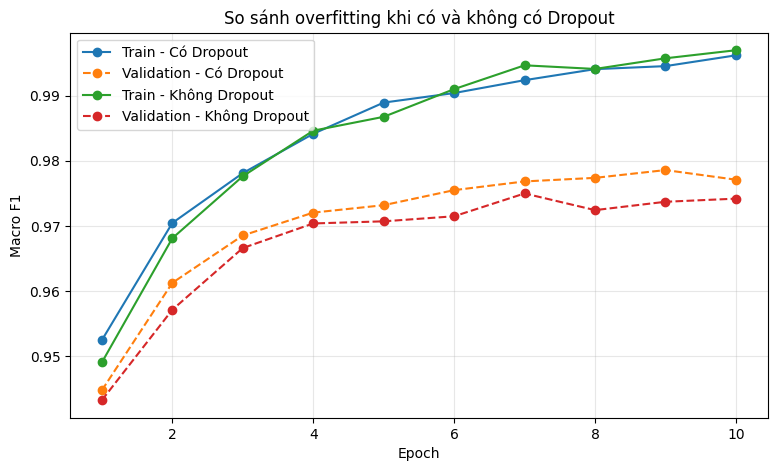

Nhận xét: Bỏ Dropout làm khoảng cách Train–Validation tăng từ 0.0191 lên 0.0228; mô hình không Dropout overfit rõ hơn.


In [5]:
experiments["mlp_adam_1e-3_no_dropout"] = run_experiment(
    name="MLP không Dropout",
    model_name="mlp",
    learning_rate=1e-3,
    optimizer_name="adam",
    use_dropout=False,
    track_train=True,
)

with_dropout = experiments["mlp_adam_1e-3_dropout"]
without_dropout = experiments["mlp_adam_1e-3_no_dropout"]

rows = []
for label, result in [("Có Dropout", with_dropout), ("Không Dropout", without_dropout)]:
    final_train_f1 = result["history"]["train_f1"][-1]
    final_validation_f1 = result["history"]["validation_f1"][-1]
    rows.append({
        "Cấu hình": label,
        "Train F1 (epoch cuối)": final_train_f1,
        "Validation F1 (epoch cuối)": final_validation_f1,
        "Khoảng cách Train - Validation": final_train_f1 - final_validation_f1,
        "Test F1": result["test_f1"],
    })

comparison_dropout = pd.DataFrame(rows)
display(
    comparison_dropout.style.format({
        "Train F1 (epoch cuối)": "{:.4f}",
        "Validation F1 (epoch cuối)": "{:.4f}",
        "Khoảng cách Train - Validation": "{:.4f}",
        "Test F1": "{:.4f}",
    })
)

plt.figure(figsize=(9, 5))
for label, result in [("Có Dropout", with_dropout), ("Không Dropout", without_dropout)]:
    epochs = np.arange(1, len(result["history"]["validation_f1"]) + 1)
    plt.plot(epochs, result["history"]["train_f1"], marker="o", label=f"Train - {label}")
    plt.plot(epochs, result["history"]["validation_f1"], marker="o", linestyle="--", label=f"Validation - {label}")
plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.title("So sánh overfitting khi có và không có Dropout")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

gap_with = comparison_dropout.loc[
    comparison_dropout["Cấu hình"] == "Có Dropout",
    "Khoảng cách Train - Validation",
].iloc[0]
gap_without = comparison_dropout.loc[
    comparison_dropout["Cấu hình"] == "Không Dropout",
    "Khoảng cách Train - Validation",
].iloc[0]

if gap_without > gap_with:
    print(
        f"Nhận xét: Bỏ Dropout làm khoảng cách Train–Validation tăng từ "
        f"{gap_with:.4f} lên {gap_without:.4f}; mô hình không Dropout overfit rõ hơn."
    )
else:
    print(
        f"Nhận xét: Trong lần chạy này, khoảng cách Train–Validation của mô hình không Dropout "
        f"({gap_without:.4f}) không lớn hơn mô hình có Dropout ({gap_with:.4f}); "
        "chưa thấy overfitting rõ trong số epoch đã chạy."
    )

## 4. Đổi optimizer từ Adam sang SGD

In [6]:
experiments["mlp_sgd_0.01_dropout"] = run_experiment(
    name="MLP SGD",
    model_name="mlp",
    learning_rate=0.01,
    optimizer_name="sgd",
    use_dropout=True,
)

comparison_optimizer = pd.DataFrame([
    {
        "Optimizer": "Adam",
        "Learning rate": experiments["mlp_adam_1e-3_dropout"]["learning_rate"],
        "Thời gian huấn luyện (giây)": experiments["mlp_adam_1e-3_dropout"]["training_seconds"],
        "F1-score (test)": experiments["mlp_adam_1e-3_dropout"]["test_f1"],
    },
    {
        "Optimizer": "SGD (momentum=0.9)",
        "Learning rate": experiments["mlp_sgd_0.01_dropout"]["learning_rate"],
        "Thời gian huấn luyện (giây)": experiments["mlp_sgd_0.01_dropout"]["training_seconds"],
        "F1-score (test)": experiments["mlp_sgd_0.01_dropout"]["test_f1"],
    },
])

display(
    comparison_optimizer.style.format({
        "Learning rate": "{:.0e}",
        "Thời gian huấn luyện (giây)": "{:.2f}",
        "F1-score (test)": "{:.4f}",
    })
)

MLP SGD: F1 test = 0.9759, thời gian = 20.09s


,Optimizer,Learning rate,Thời gian huấn luyện (giây),F1-score (test)
0,Adam,1e-03,70.86,0.9796
1,SGD (momentum=0.9),1e-02,20.09,0.9759


## 5. Ba cặp chữ số bị nhầm nhiều nhất

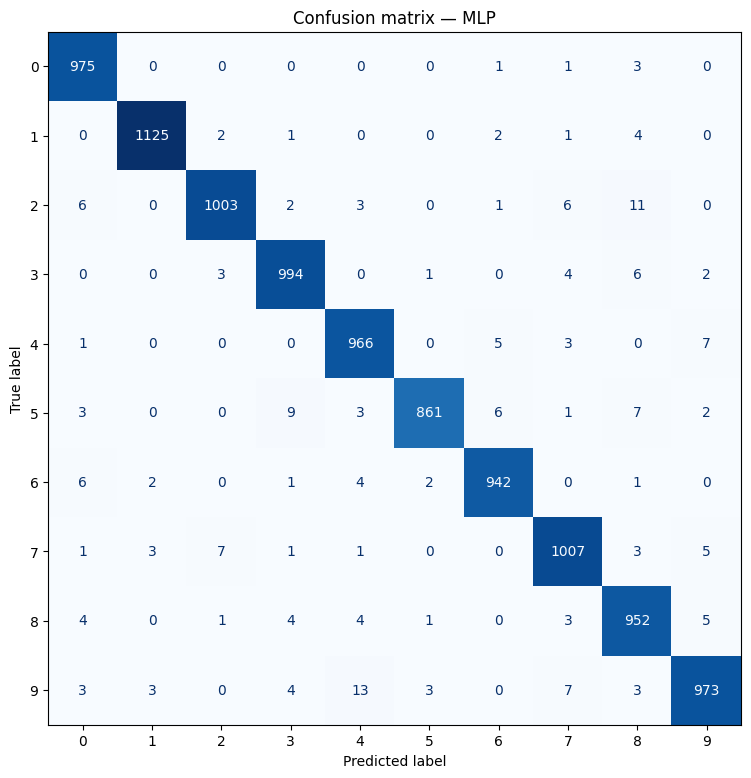

Mô hình dùng để lập confusion matrix: MLP


,Cặp chữ số,Tổng số lần nhầm,Chiều nhầm thứ nhất,Chiều nhầm thứ hai
0,4 ↔ 9,20,4 → 9: 7,9 → 4: 13
1,2 ↔ 7,13,2 → 7: 6,7 → 2: 7
2,2 ↔ 8,12,2 → 8: 11,8 → 2: 1


In [7]:
best_key, best_result = max(
    experiments.items(),
    key=lambda item: item[1]["best_validation_f1"],
)

cm = confusion_matrix(
    best_result["test_labels"],
    best_result["test_predictions"],
    labels=np.arange(10),
)

fig, ax = plt.subplots(figsize=(9, 9))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.arange(10)).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False,
)
ax.set_title(f"Confusion matrix — {best_result['name']}")
plt.show()

pairs = []
for digit_a in range(10):
    for digit_b in range(digit_a + 1, 10):
        a_to_b = int(cm[digit_a, digit_b])
        b_to_a = int(cm[digit_b, digit_a])
        pairs.append({
            "Cặp chữ số": f"{digit_a} ↔ {digit_b}",
            "Tổng số lần nhầm": a_to_b + b_to_a,
            f"{digit_a} → {digit_b}": a_to_b,
            f"{digit_b} → {digit_a}": b_to_a,
        })

pairs = sorted(pairs, key=lambda row: row["Tổng số lần nhầm"], reverse=True)[:3]

normalized_pairs = []
for row in pairs:
    pair = row["Cặp chữ số"]
    digit_a, digit_b = [int(value.strip()) for value in pair.split("↔")]
    normalized_pairs.append({
        "Cặp chữ số": pair,
        "Tổng số lần nhầm": row["Tổng số lần nhầm"],
        "Chiều nhầm thứ nhất": f"{digit_a} → {digit_b}: {cm[digit_a, digit_b]}",
        "Chiều nhầm thứ hai": f"{digit_b} → {digit_a}: {cm[digit_b, digit_a]}",
    })

top_three_pairs = pd.DataFrame(normalized_pairs)
print(f"Mô hình dùng để lập confusion matrix: {best_result['name']}")
display(top_three_pairs)